# 09 - Distância real pela malha viária (OSRM)

Desde a simulação, a distância de cada entrega é **linha reta x 1,3** (fator de tortuosidade escolhido sem medição). Aqui medimos o fator real e testamos se as conclusões mudam.

**Fonte:** OSRM (Open Source Routing Machine), servidor público de demonstração, perfil `driving`.
- **Uma única consulta** ao serviço `table`: matriz 45 x 45 entre os centros dos bairros, guardada em `data/external/osrm_bairros.csv` (este notebook só lê o cache).
- Dados de vias © colaboradores do OpenStreetMap (ODbL); roteamento: Project OSRM.
- O perfil é de **carro** e os tempos são de **via livre** (sem trânsito): servem para a distância, não para o tempo da moto.

## 1. Configuração

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd

RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "CLAUDE.md").exists())
sys.path.insert(0, str(RAIZ / "src"))

from logistica_rotas.ingestao.leitura import carregar_entregas
from logistica_rotas.limpeza.tratamento import CAMINHO_PROCESSED, limpar_entregas, salvar_parquet

pd.set_option("display.float_format", "{:.1f}".format)
pd.set_option("display.width", 140)

if not CAMINHO_PROCESSED.exists():  # Parquet fica fora do Git: gera a partir do CSV se faltar
    salvar_parquet(limpar_entregas(carregar_entregas()), CAMINHO_PROCESSED)
df = pd.read_parquet(CAMINHO_PROCESSED)

from logistica_rotas.ingestao.osrm import carregar_cache
from logistica_rotas.ingestao.simulacao import FATOR_TORTUOSIDADE, gerar_entregas
from logistica_rotas.roteirizacao.despacho import fator_por_distancia, resumo_despacho, simular_despacho
from logistica_rotas.visualizacao import graficos as g

osrm = carregar_cache()
pares = osrm[(osrm["fonte_origem"] == "osm") & (osrm["fonte_destino"] == "osm")].copy()
print(f"{len(osrm)} pares de bairros; {len(pares)} entre bairros com coordenada real")

1980 pares de bairros; 1806 entre bairros com coordenada real


## 2. Fator de tortuosidade real

In [2]:
pares["fator_tortuosidade"].describe(percentiles=[0.1, 0.25, 0.5, 0.75, 0.9]).to_frame("pela rua / linha reta")

,pela rua / linha reta
count,1806.0
mean,1.4
std,0.3
min,1.0
10%,1.2
25%,1.3
50%,1.4
75%,1.5
90%,1.7
max,6.8


In [3]:
faixa = pd.cut(pares["reta_km"], [0, 2, 4, 6, 10, 15, 30])
por_faixa = pares.groupby(faixa, observed=True).agg(pares_bairros=("fator_tortuosidade", "size"),
                                                    reta_mediana_km=("reta_km", "median"),
                                                    fator_mediano=("fator_tortuosidade", "median"))
por_faixa["ajuste_1_31_mais_0_40_sobre_d"] = fator_por_distancia(por_faixa["reta_mediana_km"].to_numpy())
por_faixa

,pares_bairros,reta_mediana_km,fator_mediano,ajuste_1_31_mais_0_40_sobre_d
reta_km,,,,
"(0, 2]",110,1.4,1.7,1.6
"(2, 4]",232,3.1,1.5,1.4
"(4, 6]",272,5.0,1.4,1.4
"(6, 10]",658,7.9,1.4,1.4
"(10, 15]",412,11.7,1.3,1.3
"(15, 30]",122,16.4,1.3,1.3


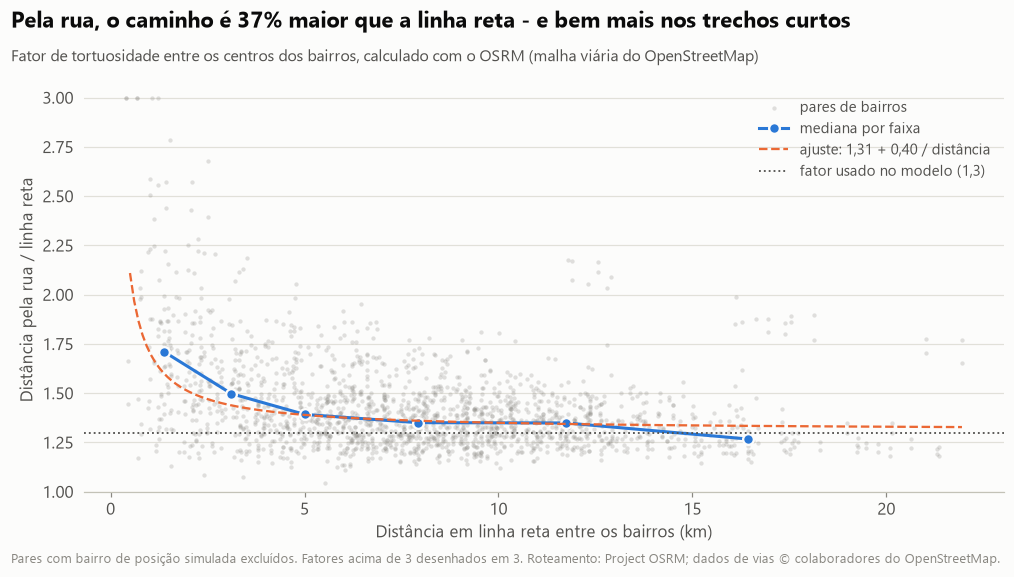

In [4]:
fig = g.fator_tortuosidade_osrm(pares, FATOR_TORTUOSIDADE)
g.salvar_figura(fig, "15_fator_tortuosidade_osrm");

In [5]:
pares.nlargest(5, "fator_tortuosidade")[["bairro_origem", "cidade_origem", "bairro_destino", "cidade_destino",
                                        "reta_km", "osrm_km", "fator_tortuosidade"]]

,bairro_origem,cidade_origem,bairro_destino,cidade_destino,reta_km,osrm_km,fator_tortuosidade
1671,Centro,Mauá,Matriz,Mauá,0.4,2.7,6.8
1973,Matriz,Mauá,Centro,Mauá,0.4,2.2,5.7
1665,Centro,Mauá,Vila Noêmia,Mauá,0.7,3.1,4.5
1709,Vila Noêmia,Mauá,Centro,Mauá,0.7,2.4,3.6
154,Campestre,Santo André,Santa Maria,São Caetano do Sul,1.1,3.2,3.0


**Leitura:**
- **O fator real é maior que 1,3.** A mediana é 1,37: pela rua, o caminho é 37% maior que a linha reta.
- **Trechos curtos são os mais afetados:** até 2 km, o fator mediano é 1,71. Contornos, mãos de direção e a falta de travessias pesam mais quando a distância é pequena. Acima de 10 km, fica em cerca de 1,33.
- **Casos extremos:** Centro e Matriz, em Mauá, ficam a 400 m em linha reta e a 2,7 km pela rua, cerca de 7 vezes mais. Um bloqueio no caminho (ferrovia, rio ou via sem cruzamento) obriga a contornar. **Verificar** no mapa qual é o obstáculo.
- **Ajuste simples:** o fator 1,31 + 0,40 / distância em linha reta (km) reproduz de perto as medianas (até 2 km fica um pouco abaixo: 1,6 contra 1,7) e foi incorporado como opção (`fator="osrm"`).

In [6]:
pd.Series({
    "velocidade mediana em via livre (km/h)": pares["velocidade_livre_kmh"].median(),
    "velocidade usada no modelo, normal (km/h)": 28.0,
    "velocidade usada no modelo, pico (km/h)": 18.0,
}).to_frame("valor")

,valor
velocidade mediana em via livre (km/h),40.4
"velocidade usada no modelo, normal (km/h)",28.0
"velocidade usada no modelo, pico (km/h)",18.0


**Leitura:** o OSRM estima 40 km/h em via livre, para carro e sem trânsito. Os 28 km/h (normal) e 18 km/h (pico) do modelo, para moto com trânsito e paradas, são coerentes com isso: mais lentos que a via livre, como esperado.

## 3. As conclusões mudam com a distância real?

Repetimos a política recomendada (notebook 08) com o fator fixo 1,3 e com o fator calibrado por distância.

In [7]:
linhas = []
for nome_volume, base in {"atual": df, "4x": gerar_entregas(n=20_000)}.items():
    for fator in [FATOR_TORTUOSIDADE, "osrm"]:
        individual = resumo_despacho(simular_despacho(base, 0, capacidade=1, fator=fator))
        dinamico = resumo_despacho(simular_despacho(base, 5, 4, 5, espera_max_pico_min=0, fator=fator), individual["km"])
        rotulo = "1,3 fixo" if fator == FATOR_TORTUOSIDADE else "calibrado (OSRM)"
        linhas.append({"volume": nome_volume, "fator": rotulo, "km individual": individual["km"],
                       "km dinâmico": dinamico["km"], "economia_km_pct": dinamico["economia_km_pct"],
                       "no prazo individual": individual["no_prazo_real_pct"],
                       "no prazo dinâmico": dinamico["no_prazo_real_pct"]})
impacto = pd.DataFrame(linhas)
impacto

,volume,fator,km individual,km dinâmico,economia_km_pct,no prazo individual,no prazo dinâmico
0,atual,"1,3 fixo",46192.3,45322.1,1.9,97.0,96.4
1,atual,calibrado (OSRM),50348.0,49455.0,1.8,96.3,94.9
2,4x,"1,3 fixo",178996.7,168827.9,5.7,97.0,95.3
3,4x,calibrado (OSRM),195543.7,185254.1,5.3,96.2,94.1


**Leitura:**
- **Quilômetros:** com o fator calibrado, o total sobe cerca de 9%. É o custo real por km que o modelo subestimava.
- **Economia:** praticamente não muda (1,8% contra 1,9% no volume atual, e 5,3% contra 5,7% com 4x). Ela é uma proporção, e o aumento atinge quase igual a operação com e sem agrupamento.
- **Prazo:** cai de 0,7 a 1,5 ponto (por exemplo, 96,3% contra 97,0% saindo na hora, e 94,9% contra 96,4% no despacho dinâmico), porque a regra de prazo foi feita com a distância antiga.
- **As conclusões dos notebooks 05 a 08 se mantêm.** Só os valores absolutos de km e de prazo ficam um pouco piores.

## 4. Conclusões

1. **O fator 1,3 subestimava a distância real** (mediana de 1,37), principalmente em trechos curtos (1,71 até 2 km).
2. **A troca do fator não muda as conclusões:** a economia relativa do despacho dinâmico fica praticamente igual e o prazo cai de 0,7 a 1,5 ponto.
3. **Recomendação para dados reais:** usar distância pela rua (OSRM ou equivalente) para custo e para definir o prazo prometido, porque a regra atual (12 min + 2,5 min/km) foi feita sobre a distância subestimada.

**Limitações:** perfil de carro e via livre (sem trânsito); a matriz é entre centros de bairro, não entre os endereços exatos; uma consulta pontual (as vias mudam com o tempo).